# AutoGluon: Predicting Employee Attrition

- This notebook builds an attrition model on the IBM HR Analytics dataset, from
  the raw CSV to a decision rule that HR could act on
- The pedagogical arc:
  - Load the data and set a logistic regression baseline
  - Train an AutoGluon ensemble and compare it with the baseline, with
    confidence intervals
  - Move the decision threshold to trade precision for recall, using
    out-of-fold predictions instead of the test set
  - Explain the model globally (permutation importance) and per employee (SHAP)
  - Summarize the predicted risk by department and job role
- The task follows "Project 2: Employee Attrition Prediction" in
  `class_project/project_descriptions/MSML610/AutoGluon_Project_Description.md`

In [1]:
%load_ext autoreload
%autoreload 2

import logging

import autogluon.tabular as agt
import numpy as np
import pandas as pd

In [2]:
import helpers.hnotebook as hnotebook

import AutoGluon_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)
# Hide the GPU probe warnings (no `torch` in the image) and the SHAP internals.
utils.silence_noisy_loggers()

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

print("autogluon.tabular version: ", agt.__version__)

INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmpx0z7thxl.json --HistoryManager.hist_file=:memory:


autogluon.tabular version:  1.6.3


# Part 1: Load and Explore the Data

## Cell 1.1: Download the Dataset

- The file is the Kaggle "IBM HR Analytics Employee Attrition" dataset, read
  from a pinned commit of IBM's GitHub repo, so no Kaggle account is needed
  - The download is cached in `data/` and checked against a SHA-256 digest
- IBM data scientists created the data: the employees are fictional
- One row per employee, `Attrition` is "Yes" when the employee left

In [3]:
# Download the CSV (once) and load it.
csv_path = utils.download_attrition_data("data")
raw_df = pd.read_csv(csv_path)
print("raw_df.shape=", raw_df.shape)
display(raw_df.head())

raw_df.shape= (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


## Cell 1.2: Drop the Columns That Carry No Signal

- AutoGluon drops constant columns by itself
  - Dropping them here keeps the tables below short
- `EmployeeNumber` is an identifier
  - AutoGluon cannot know that and would treat it as a number
  - Always remove IDs before training

In [4]:
# Find the columns with a single value.
n_unique = raw_df.nunique()
constant_cols = list(n_unique[n_unique == 1].index)
print("constant_cols=", constant_cols)

constant_cols= ['EmployeeCount', 'Over18', 'StandardHours']


In [5]:
# Remove the constant columns and the identifier.
label = "Attrition"
positive_class = "Yes"
attrition_df = raw_df.drop(columns=constant_cols + ["EmployeeNumber"])
print("attrition_df.shape=", attrition_df.shape)

attrition_df.shape= (1470, 31)


## Cell 1.3: Look at the Label

- About 1 employee in 6 left: the classes are imbalanced
  - A model that always answers "No" has an accuracy of about 84%
  - Accuracy is a poor metric here: ROC-AUC, recall, and precision tell more

In [6]:
# Count the employees who stayed and left.
display(attrition_df[label].value_counts().to_frame("n_employees"))

,n_employees
Attrition,
No,1233
Yes,237


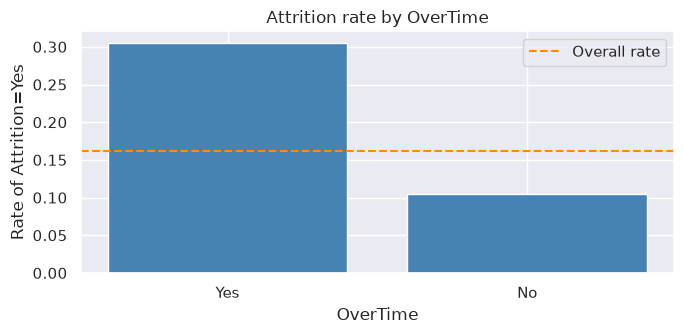

In [7]:
# Compare the attrition rate of employees with and without overtime.
utils.plot_rate_by_category(
    attrition_df, "OverTime", label, positive_class=positive_class
)
# Outcome: employees working overtime leave about 3 times as often.

# Part 2: Set a Baseline

## Cell 2.1: Split Train and Test

- 80% of the rows train the models, 20% are kept for the final evaluation
- The split is stratified on the label, so both sets keep the 16% attrition rate
- The test set has fewer than 300 employees, about 47 of whom left
  - Every test metric below is noisy (Cell 3.3)

In [8]:
# Split the data, keeping the attrition rate equal in the two sets.
train_df, test_df = utils.split_train_test(attrition_df, stratify_col=label)
print("train_df.shape=", train_df.shape)
print("test_df.shape=", test_df.shape)
print("n_left (test)=", (test_df[label] == positive_class).sum())

train_df.shape= (1176, 31)
test_df.shape= (294, 31)
n_left (test)= 47


## Cell 2.2: Train a Logistic Regression

- The baseline is what a data scientist writes by hand in a few minutes
  - One-hot encoding of the string columns
  - Scaling of the numerical columns
  - A logistic regression on top
- The code is in `utils.train_logistic_baseline()`

In [9]:
# Fit the baseline and predict the probability of leaving on the test set.
baseline = utils.train_logistic_baseline(train_df, label)
positive_idx = list(baseline.classes_).index(positive_class)
baseline_proba = baseline.predict_proba(test_df.drop(columns=[label]))[
    :, positive_idx
]
baseline_metrics = utils.compute_binary_metrics(
    test_df[label], baseline_proba, positive_class=positive_class
)
display(pd.Series(baseline_metrics, name="baseline").to_frame())
# Outcome: a ROC-AUC around 0.8, but at the 0.5 threshold the model flags only
# about 1 leaver in 3 (low recall).

,baseline
threshold,0.500000
accuracy,0.860544
precision,0.615385
recall,0.340426
f1,0.438356
roc_auc,0.811526


# Part 3: Train AutoGluon

## Cell 3.1: Fit an Ensemble

- `eval_metric="roc_auc"`: the models are ranked on how well they order the
  employees by risk
  - The threshold is chosen later, in Part 4
- `positive_class="Yes"`: probabilities and recall refer to leaving
- `presets="good_quality"`
  - Bags every model on 8 folds and fits a weighted ensemble on top
  - Refits the chosen models on all the training rows for fast inference
- `dynamic_stacking=False` skips a check that trains everything twice to
  decide whether stacking overfits
  - It doubles the training time and is not needed on 1,200 rows
- The neural networks are excluded: they need `torch`, not installed in the
  image

In [10]:
# Train the AutoGluon ensemble.
predictor = agt.TabularPredictor(
    label=label,
    eval_metric="roc_auc",
    positive_class=positive_class,
    path="tmp.autogluon/attrition",
    verbosity=1,
)
_ = predictor.fit(
    train_df,
    presets="good_quality",
    dynamic_stacking=False,
    excluded_model_types=["NN_TORCH", "FASTAI"],
    time_limit=300,
)
print("predictor.model_best=", predictor.model_best)

AutoGluon infers your prediction problem is: 'binary' (because only two unique label-values observed).


	If 'binary' is not the correct problem_type, please manually specify the problem_type parameter during Predictor init (You may specify problem_type as one of: ['binary', 'multiclass', 'regression', 'quantile'])


Will use sequential fold fitting strategy because import of ray failed. Reason: ray is required to train folds in parallel for TabularPredictor or HPO for MultiModalPredictor. A quick tip is to install via `pip install "ray>=2.43.0,<2.59.0"`


predictor.model_best= WeightedEnsemble_L2_FULL


## Cell 3.2: Read the Leaderboard

- `_BAG_L1` models were trained on 8 folds and have a validation score
  (`score_val`) computed out of fold
- `_FULL` models are the same models refit on all the training rows
  - They have no validation score of their own
  - `predictor.model_best` is the refit ensemble
- The ranking on `score_test` differs from the ranking on `score_val`
  - With 47 leavers in the test set, a few rows decide the order
  - Pick models on `score_val`, as AutoGluon does, never on `score_test`

In [11]:
# Score every model on the test set.
leaderboard_df = predictor.leaderboard(test_df)
cols = ["model", "score_test", "score_val", "stack_level", "fit_time"]
display(leaderboard_df[cols])

,model,score_test,score_val,stack_level,fit_time
0,ExtraTreesGini_BAG_L1,0.829270,0.805405,1,0.585450
1,ExtraTreesGini_BAG_L1_FULL,0.829270,NaN,1,0.585450
2,ExtraTreesEntr_BAG_L1,0.819838,0.821050,1,0.582715
3,ExtraTreesEntr_BAG_L1_FULL,0.819838,NaN,1,0.582715
4,CatBoost_BAG_L1_FULL,0.805926,NaN,1,0.285201
5,WeightedEnsemble_L2_FULL,0.798777,NaN,2,0.958539
6,LightGBMXT_BAG_L1_FULL,0.790766,NaN,1,0.156671
7,RandomForestGini_BAG_L1,0.790594,0.788857,1,0.601569
8,RandomForestGini_BAG_L1_FULL,0.790594,NaN,1,0.601569
9,XGBoost_BAG_L1_FULL,0.790077,NaN,1,0.040166


In [12]:
# Print the weight of each model in the ensemble.
ensemble_info = predictor.info()["model_info"]["WeightedEnsemble_L2"]
print("weights=", ensemble_info["children_info"]["S1F1"]["model_weights"])
# Outcome: the ensemble mixes 2 LightGBM variants and Extra Trees.

weights= {'LightGBMXT_BAG_L1': np.float64(0.38095238095238093), 'LightGBM_BAG_L1': np.float64(0.2857142857142857), 'ExtraTreesEntr_BAG_L1': np.float64(0.3333333333333333)}


## Cell 3.3: Compare With the Baseline, With Confidence Intervals

- A single test ROC-AUC on 294 rows can move by several points with another
  split
- The bootstrap resamples the test set 1,000 times and reports the range that
  contains 95% of the scores
- If the two intervals overlap widely, the test set cannot tell the two models
  apart

In [13]:
# Predict the probability of leaving with AutoGluon.
ag_proba = predictor.predict_proba(test_df)[positive_class].to_numpy()

# Compare the ROC-AUC of the two models with bootstrap intervals.
auc_df = pd.DataFrame(
    {
        "logistic_baseline": utils.bootstrap_roc_auc(
            test_df[label], baseline_proba, positive_class=positive_class
        ),
        "autogluon": utils.bootstrap_roc_auc(
            test_df[label], ag_proba, positive_class=positive_class
        ),
    }
).T.round(3)
display(auc_df)

,roc_auc,ci_low,ci_high
logistic_baseline,0.812,0.733,0.882
autogluon,0.799,0.717,0.874


- On this split the logistic baseline scores slightly higher, and the two
  intervals overlap almost completely: the test set cannot separate them
  - 1,200 rows with mostly monotonic effects (overtime, income, tenure) leave
    little room for tree ensembles to beat a linear model
  - AutoGluon reached the same level with no feature engineering, after
    searching several model families
  - Adding AutoGluon's own linear model (`"LR": {}` in `hyperparameters`) to
    the ensemble does not change the test ROC-AUC on this split, which points
    to a ceiling of the data rather than of the models
- Keep a simple baseline in every AutoML project: it tells you whether the
  complexity pays for itself

# Part 4: Choose the Decision Threshold

## Cell 4.1: The 0.5 Threshold Misses Most Leavers

- `predict()` flags an employee when the probability of leaving is at least 0.5
- With a 16% base rate few employees pass 0.5, so recall is low
- The spec asks for high recall: missing an employee who leaves is the costly
  error

In [14]:
# Compute the test metrics of AutoGluon at the default threshold.
default_metrics = utils.compute_binary_metrics(
    test_df[label], ag_proba, positive_class=positive_class
)
display(pd.Series(default_metrics, name="autogluon_at_0.5").to_frame())

,autogluon_at_0.5
threshold,0.500000
accuracy,0.857143
precision,0.727273
recall,0.170213
f1,0.275862
roc_auc,0.798777


## Cell 4.2: Calibrate the Threshold on Out-of-Fold Predictions

- Choosing the threshold on the test set would leak it into the model
- The bagged models give one out-of-fold probability per training row
  - Each probability comes from models that did not see that row
  - It is a fair stand-in for unseen data
- `calibrate_decision_threshold()` searches the threshold that maximizes a
  metric on these predictions
  - Here F1, the balance of precision and recall

In [15]:
# Search the threshold that maximizes F1 on the out-of-fold predictions.
f1_threshold = predictor.calibrate_decision_threshold(metric="f1", verbose=False)
print("f1_threshold=", round(f1_threshold, 3))

f1_threshold= 0.267


## Cell 4.3: Put a Cost on Each Error

- F1 treats a missed leaver and a false alarm as equally bad
- Assume that losing an employee costs 5 times a retention conversation
  - `fn_cost=5`: an employee leaves without being flagged
  - `fp_cost=1`: HR talks to an employee who would have stayed
  - The ratio is an assumption: replace it with your own numbers
- The cost-optimal threshold is the one with the lowest average cost on the
  out-of-fold predictions

In [16]:
# Compute the metrics and the cost of every threshold on the out-of-fold data.
oof_proba = predictor.predict_proba_oof()[positive_class]
curve_df = utils.compute_threshold_curve(
    train_df[label],
    oof_proba.to_numpy(),
    positive_class=positive_class,
    fn_cost=5,
    fp_cost=1,
)
cost_threshold = float(curve_df.loc[curve_df["cost"].idxmin(), "threshold"])
print("cost_threshold=", round(cost_threshold, 3))

cost_threshold= 0.16


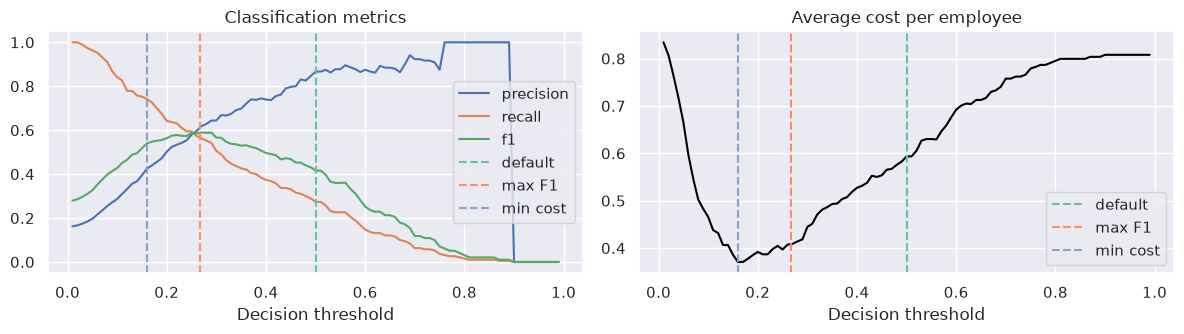

In [17]:
# Plot precision, recall, F1, and cost against the threshold.
thresholds = {
    "default": 0.5,
    "max F1": f1_threshold,
    "min cost": cost_threshold,
}
utils.plot_threshold_curve(curve_df, marked_thresholds=thresholds)
# Outcome: lowering the threshold raises recall and lowers precision; the cost
# is lowest well below 0.5.

## Cell 4.4: Evaluate the Three Thresholds on the Test Set

- The thresholds were chosen without the test set, so these numbers are a fair
  estimate
- ROC-AUC does not change: it does not depend on the threshold

In [18]:
# Compare test metrics and cost for the three thresholds.
rows = {}
for name, threshold in thresholds.items():
    metrics = utils.compute_binary_metrics(
        test_df[label],
        ag_proba,
        positive_class=positive_class,
        threshold=threshold,
    )
    metrics["cost"] = utils.compute_expected_cost(
        test_df[label],
        ag_proba,
        positive_class=positive_class,
        threshold=threshold,
        fn_cost=5,
        fp_cost=1,
    )
    rows[name] = metrics
threshold_df = pd.DataFrame(rows).T.round(3)
display(threshold_df)

,threshold,accuracy,precision,recall,f1,roc_auc,cost
default,0.500,0.857,0.727,0.170,0.276,0.799,0.673
max F1,0.267,0.837,0.490,0.532,0.510,0.799,0.463
min cost,0.160,0.769,0.376,0.681,0.485,0.799,0.435


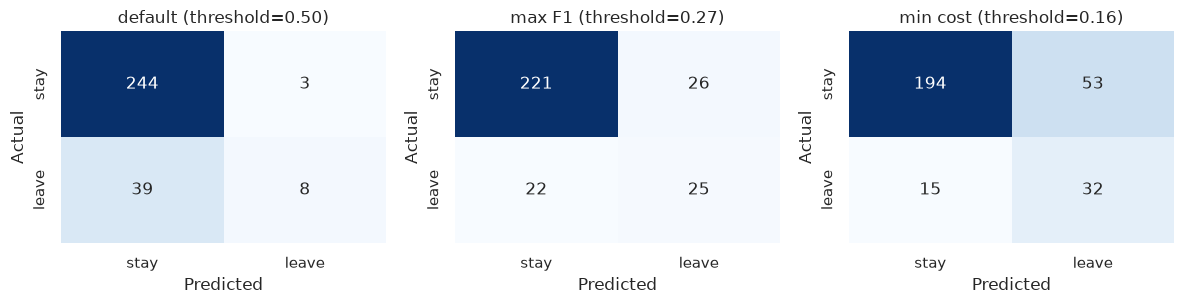

In [19]:
# Show the confusion matrix of each threshold.
utils.plot_confusion_matrices(
    test_df[label],
    ag_proba,
    positive_class=positive_class,
    thresholds=thresholds,
)
# Outcome: the lower thresholds catch most leavers, at the price of more false
# alarms.

## Cell 4.5: Store the Threshold in the Predictor

- `set_decision_threshold()` makes `predict()` use the new threshold
  - It is saved with the predictor, so a deployed copy behaves the same

In [20]:
# Make `predict()` use the cost-optimal threshold.
predictor.set_decision_threshold(cost_threshold)
n_flagged = (predictor.predict(test_df) == positive_class).sum()
print("predictor.decision_threshold=", round(predictor.decision_threshold, 3))
print("n_flagged (test)=", n_flagged)

predictor.decision_threshold= 0.16
n_flagged (test)= 85


# Part 5: Explain the Model

## Cell 5.1: Global View With Permutation Importance

- Shuffle one column, measure the drop of ROC-AUC on the test set
- A `p_value` below 0.05 means the drop is unlikely to be noise
- Importance measures what the model relies on, not what causes attrition

In [21]:
# Compute the permutation importance on the test set.
importance_df = predictor.feature_importance(test_df, num_shuffle_sets=3)
display(importance_df.head(10))

,importance,stddev,p_value,n,p99_high,p99_low
OverTime,0.109283,0.031743,0.013495,3,0.291173,-0.072607
EnvironmentSatisfaction,0.019496,0.004976,0.010517,3,0.048011,-0.009018
StockOptionLevel,0.016826,0.008356,0.036644,3,0.064708,-0.031056
JobSatisfaction,0.015448,0.002305,0.003671,3,0.028658,0.002237
JobLevel,0.010911,0.002622,0.009353,3,0.025934,-0.004112
MaritalStatus,0.009992,0.008069,0.082572,3,0.056229,-0.036245
JobInvolvement,0.008356,0.001048,0.002601,3,0.014360,0.002351
RelationshipSatisfaction,0.007982,0.008016,0.113360,3,0.053916,-0.037952
DistanceFromHome,0.007552,0.006423,0.089325,3,0.044358,-0.029254
BusinessTravel,0.007207,0.001617,0.008183,3,0.016472,-0.002058


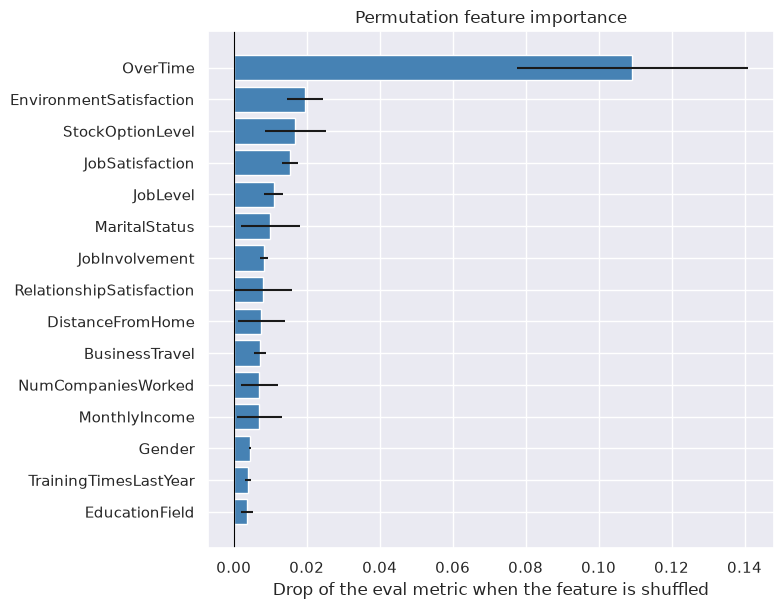

In [22]:
# Plot the most important features.
utils.plot_feature_importance(importance_df)
# Outcome: `OverTime` is by far the most important feature, as Cell 1.3
# suggested.

## Cell 5.2: Explain One Employee With SHAP

- SHAP splits a single prediction into one contribution per feature
  - Baseline: the average predicted probability on a background sample
  - Baseline plus the contributions equals the prediction of this employee
- Kernel SHAP only calls `predict_proba()`, so it explains the whole ensemble
  - It is slow: it evaluates `n_samples` perturbed rows per explained row
  - A background of 30 training rows keeps it fast

In [23]:
# Background data: the reference rows of Kernel SHAP.
#
# - SHAP replaces some features of the explained row with background values and
#   measures the change in the prediction
# - 30 rows is a coarse but fast estimate of the "average employee"
# - More rows give more stable contributions and cost linearly more time
features_df = train_df.drop(columns=[label])
test_features_df = test_df.drop(columns=[label])
background_df = features_df.sample(30, random_state=0)
print("background_df.shape=", background_df.shape)

background_df.shape= (30, 30)


In [24]:
# Explain the test employee with the highest predicted risk.
top_idx = int(np.argmax(ag_proba))
top_row_df = test_features_df.iloc[[top_idx]]
top_shap_df = utils.explain_with_kernel_shap(
    predictor, background_df, top_row_df, positive_class=positive_class
)
expected_value = top_shap_df.attrs["expected_value"]
print("predicted probability=", round(ag_proba[top_idx], 3))
print("expected_value=", round(expected_value, 3))
print(
    "expected_value + sum(contributions)=",
    round(expected_value + top_shap_df.iloc[0].sum(), 3),
)

predicted probability= 0.903
expected_value= 0.264
expected_value + sum(contributions)= 0.903


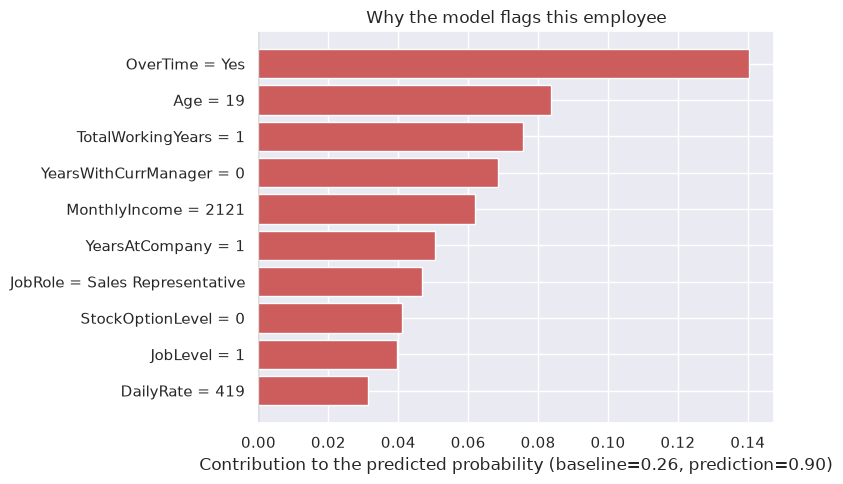

In [25]:
# Plot the largest contributions for this employee.
utils.plot_shap_contributions(
    top_shap_df.iloc[0],
    top_row_df.iloc[0],
    expected_value=expected_value,
    title="Why the model flags this employee",
)
# Outcome: red bars push the risk up and blue bars push it down. For this
# employee all the top contributions push it up, led by `OverTime = Yes` and a
# young age with little work experience.

## Cell 5.3: From Local to Global SHAP

- Averaging the absolute contributions over many employees gives a global
  ranking
- It should broadly agree with the permutation importance of Cell 5.1
  - Both describe the same model with different methods

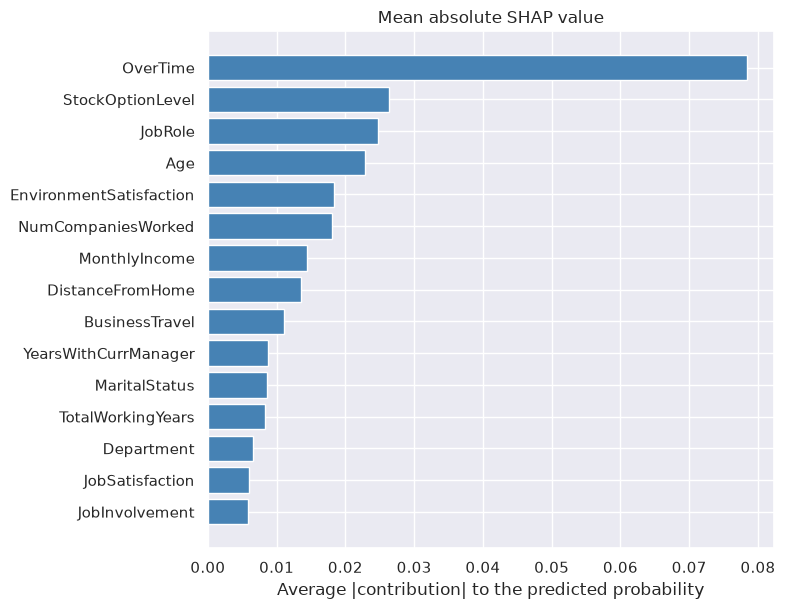

In [26]:
# Explain 50 test employees and rank the features by average contribution.
sample_df = test_features_df.sample(50, random_state=0)
sample_shap_df = utils.explain_with_kernel_shap(
    predictor, background_df, sample_df, positive_class=positive_class
)
utils.plot_mean_abs_shap(sample_shap_df)

# Part 6: Summarize the Risk by Group

## Cell 6.1: Risk by Department and Job Role

- The predicted risk of each test employee is averaged by group
- `actual_rate` is the observed attrition in the same test rows
  - Groups with few employees have noisy rates: check `n_employees`

In [27]:
# Average the predicted risk by department.
display(
    utils.summarize_risk_by(
        test_df, ag_proba, "Department", label, positive_class=positive_class
    )
)

,n_employees,predicted_risk,actual_rate
Department,,,
Sales,82,0.199,0.195
Human Resources,15,0.130,0.133
Research & Development,197,0.123,0.147


In [28]:
# Average the predicted risk by job role.
display(
    utils.summarize_risk_by(
        test_df, ag_proba, "JobRole", label, positive_class=positive_class
    )
)
# Outcome: sales representatives have the highest predicted and observed
# attrition.

,n_employees,predicted_risk,actual_rate
JobRole,,,
Sales Representative,23,0.333,0.348
Laboratory Technician,44,0.172,0.091
Research Scientist,72,0.159,0.250
Human Resources,11,0.158,0.182
Sales Executive,53,0.158,0.151
Healthcare Representative,23,0.084,0.130
Manufacturing Director,32,0.065,0.094
Research Director,17,0.053,0.059
Manager,19,0.041,0.000


## Cell 6.2: Limits of This Model

- The data is fictional and small
  - Use it to learn the workflow, not to draw conclusions about real employees
- The features include `Age`, `Gender`, and `MaritalStatus`
  - A real HR model must be checked for unfair treatment of protected groups
    before anyone acts on its scores
- The model ranks risk: it does not say why people leave or what would keep
  them
  - Answering that needs causal analysis or experiments

## Summary: The Mental Model

- AutoGluon turns a raw table into a validated ensemble in one `fit()` call, but
  the choices around it stay with you
  - Remove identifiers, pick the metric, and keep a simple baseline
- On small tables, report confidence intervals: the gap between models is often
  smaller than the noise of the test set
- The model gives probabilities, the decision needs a threshold
  - Choose it on out-of-fold predictions with a metric or a cost that reflects
    the business, then store it with `set_decision_threshold()`
- Permutation importance explains what the model uses overall, SHAP explains
  single predictions; neither one explains causes